In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
!pip install -q --upgrade "transformers==5.15.1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 81.1 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 25.9 MB/s eta 0:00:00


In [2]:
import transformers

print("Transformers version:")
print(transformers.__version__)

print()

import transformers.utils.generic as generic

print(
    "Has merge_with_config_defaults:",
    hasattr(
        generic,
        "merge_with_config_defaults",
    ),
)

Transformers version:
5.15.1

Has merge_with_config_defaults: True


In [ ]:
# ============================================================
# LOGIN HF + RESET GPU + LOAD MODEL
# ============================================================

import gc
import torch

from huggingface_hub import login
from transformers import AutoModelForCausalLM


# ============================================================
# CONFIG
# ============================================================


HF_REPO = (
    "adaptive-retrieval-timing/"
    "ART-Attention-Mixing-Probe"
)


# ============================================================
# 1. HUGGING FACE LOGIN
# ============================================================

print("=" * 80)
print("1. HUGGING FACE LOGIN")
print("=" * 80)

login(
    token=HF_TOKEN,
    add_to_git_credential=False,
)

print("✓ Hugging Face login successful")
print()


# ============================================================
# 2. RESET GPU
# ============================================================

print("=" * 80)
print("2. RESET GPU")
print("=" * 80)

# Delete model if it somehow exists
if "probe" in globals():
    del probe

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

print("✓ GPU cache cleared")
print()


# ============================================================
# 3. GPU MEMORY AFTER RESET
# ============================================================

print("=" * 80)
print("3. GPU MEMORY AFTER RESET")
print("=" * 80)

if torch.cuda.is_available():

    for i in range(torch.cuda.device_count()):

        allocated = (
            torch.cuda.memory_allocated(i)
            / 1024**3
        )

        reserved = (
            torch.cuda.memory_reserved(i)
            / 1024**3
        )

        print(f"GPU {i}:")
        print(f"  Allocated: {allocated:.2f} GB")
        print(f"  Reserved : {reserved:.2f} GB")

else:
    print("CUDA is not available.")

print()


# ============================================================
# 4. LOAD MODEL FROM HUGGING FACE
# ============================================================

print("=" * 80)
print("4. LOAD MODEL FROM HUGGING FACE")
print("=" * 80)

print("Repository:")
print(HF_REPO)
print()

probe = AutoModelForCausalLM.from_pretrained(
    HF_REPO,

    torch_dtype=torch.bfloat16,

    device_map="cuda",

    trust_remote_code=True,
    attn_implementation="eager",
)

print()
print("✓ Model loaded")
print()


# ============================================================
# 5. MODEL CLASS
# ============================================================

print("=" * 80)
print("5. MODEL CLASS")
print("=" * 80)

print("type:")
print(type(probe))

print()

print("class name:")
print(probe.__class__.__name__)

print()


# ============================================================
# 6. MODEL DEVICE / DTYPE
# ============================================================

print("=" * 80)
print("6. MODEL DEVICE / DTYPE")
print("=" * 80)

first_param = next(probe.parameters())

print("device:")
print(first_param.device)

print()

print("dtype:")
print(first_param.dtype)

print()


# ============================================================
# 7. GPU MEMORY AFTER LOAD
# ============================================================

print("=" * 80)
print("7. GPU MEMORY AFTER LOAD")
print("=" * 80)

for i in range(torch.cuda.device_count()):

    allocated = (
        torch.cuda.memory_allocated(i)
        / 1024**3
    )

    reserved = (
        torch.cuda.memory_reserved(i)
        / 1024**3
    )

    print(f"GPU {i}:")
    print(f"  Allocated: {allocated:.2f} GB")
    print(f"  Reserved : {reserved:.2f} GB")

print()


# ============================================================
# 8. FINAL CHECK
# ============================================================

print("=" * 80)
print("8. FINAL CHECK")
print("=" * 80)

assert probe.__class__.__name__ == (
    "AttentionMixingProbeForCausalLM"
)

assert first_param.device.type == "cuda"

print("✓ Correct custom model class loaded")
print("✓ Model is on GPU")
print("✓ Model dtype:", first_param.dtype)

print()
print("=" * 80)
print("LOAD TEST DONE")
print("=" * 80)

1. HUGGING FACE LOGIN
✓ Hugging Face login successful

2. RESET GPU
✓ GPU cache cleared

3. GPU MEMORY AFTER RESET
GPU 0:
  Allocated: 0.00 GB
  Reserved : 0.00 GB
GPU 1:
  Allocated: 0.00 GB
  Reserved : 0.00 GB

4. LOAD MODEL FROM HUGGING FACE
Repository:
adaptive-retrieval-timing/ART-Attention-Mixing-Probe



config.json: 0.00B [00:00, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.py: 0.00B [00:00, ?B/s]

decoder_layer.py: 0.00B [00:00, ?B/s]

attention_mixing.py: 0.00B [00:00, ?B/s]

... (2 outputs left out)

model.safetensors:   0%|          | 0.00/8.04G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/205 [00:00<?, ?B/s]


✓ Model loaded

5. MODEL CLASS
type:
<class 'transformers_modules.adaptive_hyphen_retrieval_hyphen_timing.ART_hyphen_Attention_hyphen_Mixing_hyphen_Probe.7b0717fe8068d0ff108de3d350fdb0e829c99e4b.model.AttentionMixingProbeForCausalLM'>

class name:
AttentionMixingProbeForCausalLM

6. MODEL DEVICE / DTYPE
device:
cuda:0

dtype:
torch.bfloat16

7. GPU MEMORY AFTER LOAD
GPU 0:
  Allocated: 7.49 GB
  Reserved : 7.50 GB
GPU 1:
  Allocated: 0.00 GB
  Reserved : 0.00 GB

8. FINAL CHECK
✓ Correct custom model class loaded
✓ Model is on GPU
✓ Model dtype: torch.bfloat16

LOAD TEST DONE


In [5]:
# ============================================================
# BASELINE TEST — RETRIEVAL DURING REASONING
#
# Goal:
#   Simulate a benchmark-style QA setting where the model
#   reasons about a question, receives a retrieved document
#   MID-GENERATION, and then continues reasoning before
#   producing a concise final answer.
#
# Pipeline:
#
#   QUESTION + REASONING / FINAL ANSWER INSTRUCTION
#       ↓
#   apply_chat_template()
#       ↓
#   initial assistant generation
#       ↓
#   simulated partial reasoning
#       ↓
#   retrieved document inserted
#       ↓
#   model continues reasoning
#       ↓
#   model naturally produces:
#
#       Answer: <short answer>
#
# IMPORTANT:
#   - No document_attention_mask
#   - No retrieval_decision
#   - Vanilla model
#   - Thinking disabled at chat-template level
#   - Greedy decoding
#   - Chat template applied ONLY ONCE
#   - NO continuation instruction after document
#   - "Answer:" is NOT part of simulated generation
#   - Model must naturally generate the final Answer:
#   - MAX_NEW_TOKENS = 512
#
# This tests whether a vanilla causal LM can consume
# information inserted MID-REASONING and then naturally
# complete its reasoning and produce a concise final answer.
# ============================================================


import torch
import inspect

from transformers import AutoTokenizer


# ============================================================
# 1. CONFIG
# ============================================================

QWEN_REPO = "Qwen/Qwen3-4B"

MAX_NEW_TOKENS = 512

DEVICE = next(
    probe.parameters()
).device


# ============================================================
# 2. TOKENIZER
# ============================================================

print("=" * 80)
print("1. LOAD TOKENIZER")
print("=" * 80)

tokenizer = AutoTokenizer.from_pretrained(
    QWEN_REPO,
)

print("✓ Tokenizer loaded")
print()


# ============================================================
# 3. DOCUMENT
# ============================================================

DOCUMENT = (
    "The Aster Vale Observatory maintains records of "
    "unusual atmospheric signals collected from several "
    "remote monitoring stations. "

    "Station 3 is primarily used for measuring wind "
    "pressure, while Station 6 is equipped with a "
    "narrow-band optical sensor. "

    "Lena Orin led the fourth Aster Vale expedition "
    "and spent most of the survey comparing optical "
    "readings from the remote stations. "

    "In the private expedition record, Lena Orin first "
    "marked an observation with the signal code K-417. "
    "The same record states that K-417 was the identifier "
    "assigned to a blue-shifted pulse detected by the "
    "narrow-band optical sensor. "

    "A later entry links that blue-shifted pulse "
    "specifically to the measurement taken at Station 6, "
    "where the signal appeared for eleven seconds before "
    "disappearing. Lena therefore classified the Station 6 "
    "observation as a blue-shifted pulse rather than an "
    "ordinary atmospheric fluctuation."
)


# ============================================================
# 4. QUESTION
#
# The instruction allows reasoning to be as long as needed,
# but asks for a concise final answer explicitly marked with
# "Answer:".
#
# IMPORTANT:
#   The instruction does NOT tell the model when to retrieve.
#   The retrieval event is simulated externally.
# ============================================================

QUESTION = (
    "According to Lena Orin's private expedition record, "
    "what type of phenomenon did she identify at Station 6? "
    "Reason about the question as needed, and at the end "
    "provide a concise final answer in the form "
    "\"Answer: <short answer>\"."
)

TARGET_ANSWER = "blue-shifted pulse"


# ============================================================
# 5. APPLY CHAT TEMPLATE — ONCE
# ============================================================

print("=" * 80)
print("2. APPLY CHAT TEMPLATE")
print("=" * 80)

messages = [
    {
        "role": "user",
        "content": QUESTION,
    }
]

base_text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False,
)

print("[INITIAL CHAT]")
print("-" * 80)

print(
    base_text
)

print("-" * 80)
print()


# ============================================================
# 6. SIMULATED PARTIAL REASONING
#
# This simulates the model having already generated some
# reasoning BEFORE retrieval happens.
#
# IMPORTANT:
#
#   There is NO "Answer:" here.
#
# The model has NOT reached the final answer yet.
#
# Retrieval occurs while the model is still reasoning.
# ============================================================

SIMULATED_GENERATION = (
    "I need to determine which phenomenon was associated "
    "with the observation at Station 6. The question refers "
    "specifically to Lena Orin's private expedition record, "
    "so I should identify the signal or observation that "
    "was linked to Station 6. The information available so "
    "far is not sufficient to determine the exact phenomenon."
)


print("=" * 80)
print("3. SIMULATED PARTIAL REASONING")
print("=" * 80)

print(
    "This text simulates reasoning that the model has already "
    "generated before retrieval:"
)

print("-" * 80)

print(
    SIMULATED_GENERATION
)

print("-" * 80)

print()


# ============================================================
# 7. RETRIEVED DOCUMENT
#
# The document is inserted AFTER the partial reasoning.
#
# There is intentionally:
#
#   - no "Answer:"
#   - no continuation instruction
#   - no new user message
#   - no second chat template
#
# The model must naturally continue from this context.
# ============================================================

DOCUMENT_INSERTION = (
    "\n\n"
    "[Retrieved document]\n"
    f"{DOCUMENT}\n"
    "[End retrieved document]\n\n"
)


# ============================================================
# 8. BUILD MID-REASONING CONTEXT
#
# Final structure:
#
#   QUESTION
#       ↓
#   CHAT TEMPLATE
#       ↓
#   PARTIAL REASONING
#       ↓
#   RETRIEVED DOCUMENT
#       ↓
#   MODEL CONTINUES
#       ↓
#   MORE REASONING
#       ↓
#   Answer: <short answer>
#
# ============================================================

print("=" * 80)
print("4. BUILD MID-REASONING CONTEXT")
print("=" * 80)

full_text = (
    base_text
    + SIMULATED_GENERATION
    + DOCUMENT_INSERTION
)

print(
    full_text
)

print()


# ============================================================
# 9. SHOW CONTEXT STRUCTURE
# ============================================================

print("=" * 80)
print("5. CONTEXT STRUCTURE")
print("=" * 80)

print(
    "QUESTION + REASONING / FINAL ANSWER INSTRUCTION"
)

print(
    "   ↓"
)

print(
    "CHAT TEMPLATE"
)

print(
    "   ↓"
)

print(
    "SIMULATED PARTIAL REASONING"
)

print(
    "   ↓"
)

print(
    "RETRIEVED DOCUMENT INSERTED"
)

print(
    "   ↓"
)

print(
    "MODEL CONTINUES REASONING"
)

print(
    "   ↓"
)

print(
    "MODEL GENERATES Answer: <short answer>"
)

print()


# ============================================================
# 10. TOKENIZE FINAL CONTEXT
#
# The complete modified context is tokenized ONCE.
#
# No second chat template.
# ============================================================

print("=" * 80)
print("6. TOKENIZE FINAL CONTEXT")
print("=" * 80)

inputs = tokenizer(
    full_text,
    return_tensors="pt",
    add_special_tokens=False,
)

input_ids = inputs.input_ids.to(
    DEVICE
)

attention_mask = inputs.attention_mask.to(
    DEVICE
)

B, L = input_ids.shape

print(
    "input_ids shape:",
    input_ids.shape
)

print(
    "attention_mask shape:",
    attention_mask.shape
)

print(
    "B:",
    B
)

print(
    "L:",
    L
)

print()


# ============================================================
# 11. VERIFY COMPONENTS EXIST IN INPUT
# ============================================================

print("=" * 80)
print("7. INPUT INTEGRITY")
print("=" * 80)

decoded_input = tokenizer.decode(
    input_ids[0].tolist(),
    skip_special_tokens=False,
)

assert (
    QUESTION
    in decoded_input
)

assert (
    SIMULATED_GENERATION
    in decoded_input
)

assert (
    DOCUMENT
    in decoded_input
)

# IMPORTANT:
# The simulated prefix must NOT contain "Answer:".

assert (
    "Answer:"
    not in SIMULATED_GENERATION
)

print(
    "✓ Question + reasoning/final-answer instruction "
    "exists in input_ids"
)

print(
    "✓ Simulated partial reasoning exists in input_ids"
)

print(
    "✓ Retrieved document exists in input_ids"
)

print(
    "✓ Simulated reasoning does NOT contain 'Answer:'"
)

print()


# ============================================================
# 12. FIND DOCUMENT POSITION
# ============================================================

print("=" * 80)
print("8. DOCUMENT POSITION")
print("=" * 80)

document_start_char = full_text.find(
    DOCUMENT
)

if document_start_char == -1:
    raise RuntimeError(
        "DOCUMENT was not found in full_text."
    )

document_end_char = (
    document_start_char
    + len(DOCUMENT)
)

print(
    "Document character start:",
    document_start_char
)

print(
    "Document character end:",
    document_end_char
)

print()


# ============================================================
# 13. MODEL CHECK
# ============================================================

print("=" * 80)
print("9. MODEL CHECK")
print("=" * 80)

attention_class = (
    probe.model.layers[0]
    .self_attn.__class__
)

print(
    "Model class:"
)

print(
    probe.__class__
)

print()

print(
    "Attention class:"
)

print(
    attention_class
)

print()

print(
    "Attention source:"
)

print(
    inspect.getfile(
        attention_class
    )
)

print()

print(
    "Model dtype:",
    next(probe.parameters()).dtype
)

print(
    "Model device:",
    next(probe.parameters()).device
)

print()


# ============================================================
# 14. VANILLA FORWARD
#
# NO:
#   document_attention_mask
#   retrieval_decision
#
# This is the vanilla attention path.
# ============================================================

print("=" * 80)
print("10. VANILLA FORWARD")
print("=" * 80)

with torch.no_grad():

    outputs = probe(
        input_ids=input_ids,
        attention_mask=attention_mask,
        use_cache=False,
    )

print(
    "✓ Forward successful"
)

print()

print(
    "logits shape:",
    outputs.logits.shape
)

print()


# ============================================================
# 15. NEXT TOKEN
# ============================================================

print("=" * 80)
print("11. NEXT TOKEN")
print("=" * 80)

next_token_logits = (
    outputs.logits[:, -1, :]
)

next_token_id = (
    next_token_logits.argmax(
        dim=-1
    )
)

next_token = tokenizer.decode(
    next_token_id
)

print(
    "Next token:",
    repr(next_token)
)

print(
    "Next token ID:",
    next_token_id.tolist()
)

print()


# ============================================================
# 16. CONTINUE GENERATION
#
# The model now continues directly from:
#
#   partial reasoning
#       ↓
#   retrieved document
#       ↓
#   model continuation
#
# There is NO continuation instruction.
#
# The model is expected to:
#
#   1. Continue reasoning if necessary
#   2. Eventually generate:
#
#      Answer: blue-shifted pulse
#
# ============================================================

print("=" * 80)
print("12. CONTINUE GENERATION")
print("=" * 80)

print(
    "The model now continues generation directly from "
    "the context containing the retrieved document."
)

print()

with torch.no_grad():

    generated_ids = probe.generate(
        input_ids=input_ids,
        attention_mask=attention_mask,

        max_new_tokens=MAX_NEW_TOKENS,

        do_sample=False,

        use_cache=False,
    )

print(
    "✓ Generation completed"
)

print()


# ============================================================
# 17. DECODE ONLY NEW TOKENS
# ============================================================

new_token_ids = generated_ids[
    0,
    input_ids.shape[1]:
]

generated_text = tokenizer.decode(
    new_token_ids,
    skip_special_tokens=True,
)


# ============================================================
# 18. PRINT GENERATED CONTINUATION
# ============================================================

print("=" * 80)
print("13. MODEL GENERATED CONTINUATION")
print("=" * 80)

print()

print(
    "Simulated reasoning:"
)

print("-" * 80)

print(
    SIMULATED_GENERATION
)

print("-" * 80)

print()

print(
    "Model continuation after retrieval:"
)

print("-" * 80)

print(
    generated_text
)

print("-" * 80)

print()


# ============================================================
# 19. FULL GENERATION SEQUENCE
#
# Reconstruct the sequence around the retrieval event.
# ============================================================

full_generation = (
    SIMULATED_GENERATION
    + DOCUMENT_INSERTION
    + generated_text
)

print("=" * 80)
print("14. FULL GENERATION SEQUENCE")
print("=" * 80)

print(
    "-" * 80
)

print(
    full_generation
)

print(
    "-" * 80
)

print()


# ============================================================
# 20. FIND FINAL ANSWER
#
# We specifically look for "Answer:" in the MODEL
# CONTINUATION, not in the document.
#
# This determines whether the model actually reached
# the requested final-answer format.
# ============================================================

answer_marker = "Answer:"

answer_position = (
    generated_text.find(
        answer_marker
    )
)

answer_found = (
    answer_position != -1
)


print("=" * 80)
print("15. FINAL ANSWER FORMAT CHECK")
print("=" * 80)

print(
    "Answer marker:",
    repr(answer_marker)
)

print()

print(
    "Answer marker found in model continuation:",
    answer_found
)

if answer_found:

    answer_text = generated_text[
        answer_position
        + len(answer_marker):
    ].strip()

    print()

    print(
        "Extracted final answer:"
    )

    print(
        "-" * 80
    )

    print(
        answer_text
    )

    print(
        "-" * 80
    )

else:

    answer_text = ""

    print()

    print(
        "⚠ Model did not generate an 'Answer:' marker."
    )

print()


# ============================================================
# 21. TARGET ANSWER CHECK
#
# IMPORTANT:
#
# The target answer must be found in the MODEL'S
# CONTINUATION / FINAL ANSWER, not merely inside the
# retrieved document.
# ============================================================

target_found_in_continuation = (
    TARGET_ANSWER.lower()
    in generated_text.lower()
)

target_found_in_final_answer = (
    TARGET_ANSWER.lower()
    in answer_text.lower()
)


print("=" * 80)
print("16. TARGET ANSWER CHECK")
print("=" * 80)

print(
    "Target answer:",
    TARGET_ANSWER
)

print()

print(
    "Target found in model continuation:",
    target_found_in_continuation
)

print(
    "Target found in extracted final answer:",
    target_found_in_final_answer
)

print()


# ============================================================
# 22. GENERATION STATISTICS
# ============================================================

print("=" * 80)
print("17. GENERATION STATISTICS")
print("=" * 80)

print(
    "Input tokens:",
    input_ids.shape[1]
)

print(
    "Generated tokens:",
    new_token_ids.shape[0]
)

print(
    "Total tokens:",
    generated_ids.shape[1]
)

print(
    "Maximum new tokens:",
    MAX_NEW_TOKENS
)

print()


# ============================================================
# 23. EXPERIMENT REPORT
# ============================================================

print("=" * 80)
print("18. EXPERIMENT REPORT")
print("=" * 80)

print()

print(
    "Model:"
)

print(
    probe.__class__.__name__
)

print()

print(
    "Question:"
)

print(
    QUESTION
)

print()

print(
    "Initial chat template:"
)

print(
    "APPLIED ONCE"
)

print()

print(
    "Reasoning:"
)

print(
    "ALLOWED BEFORE FINAL ANSWER"
)

print()

print(
    "Simulated generation:"
)

print(
    "PARTIAL REASONING — NO FINAL ANSWER YET"
)

print()

print(
    "Document insertion:"
)

print(
    "DURING REASONING"
)

print()

print(
    "Document accessible:"
)

print(
    "YES — vanilla causal attention"
)

print()

print(
    "Document attention mask:"
)

print(
    "NONE"
)

print()

print(
    "Retrieval decision:"
)

print(
    "NONE"
)

print()

print(
    "Thinking:"
)

print(
    "DISABLED"
)

print()

print(
    "Decoding:"
)

print(
    "GREEDY"
)

print()

print(
    "Maximum new tokens:"
)

print(
    MAX_NEW_TOKENS
)

print()

print(
    "Expected final format:"
)

print(
    "Answer: <short answer>"
)

print()

print(
    "Answer marker generated:"
)

print(
    answer_found
)

print()

print(
    "Target answer:"
)

print(
    TARGET_ANSWER
)

print()

print(
    "Target found in continuation:"
)

print(
    target_found_in_continuation
)

print()

print(
    "Target found in final answer:"
)

print(
    target_found_in_final_answer
)

print()

print(
    "=" * 80
)

print(
    "VANILLA MID-REASONING DOCUMENT TEST DONE"
)

print(
    "=" * 80
)

1. LOAD TOKENIZER
✓ Tokenizer loaded

2. APPLY CHAT TEMPLATE
[INITIAL CHAT]
--------------------------------------------------------------------------------
<|im_start|>user
According to Lena Orin's private expedition record, what type of phenomenon did she identify at Station 6? Reason about the question as needed, and at the end provide a concise final answer in the form "Answer: <short answer>".<|im_end|>
<|im_start|>assistant
<think>

</think>


--------------------------------------------------------------------------------

3. SIMULATED PARTIAL REASONING
This text simulates reasoning that the model has already generated before retrieval:
--------------------------------------------------------------------------------
I need to determine which phenomenon was associated with the observation at Station 6. The question refers specifically to Lena Orin's private expedition record, so I should identify the signal or observation that was linked to Station 6. The information available so

In [6]:
# ============================================================
# RETRIEVAL PRESSURE TEST
#
# HYPOTHESIS 1
#
# Goal:
#
#   Test whether progressively changing the retrieval decision
#   produces an ordered change in the amount of document
#   information available to the model, without destroying
#   language generation ability.
#
#
# Experimental setup:
#
#   QUESTION
#       ↓
#   CHAT TEMPLATE
#       ↓
#   PARTIAL REASONING
#       ↓
#   RETRIEVED DOCUMENT
#       ↓
#   MODEL CONTINUES REASONING
#       ↓
#   Answer: <short answer>
#
#
# The retrieved document is physically present in input_ids,
# but the target information span is selectively controlled
# through document_attention_mask + retrieval_decision.
#
#
# We sweep 20 retrieval decision values.
#
# For every decision value we measure:
#
#   - Exact Match (EM)
#   - Token-level F1
#   - Answer marker found
#   - Target found in continuation
#   - Target found in final answer
#   - Generated output
#
#
# Results are saved to:
#
#   results/
#       retrieval_pressure_test_results.json
#       retrieval_pressure_test_results.csv
#
#
# These files can later be loaded directly for plotting.
#
#
# IMPORTANT:
#
#   - Vanilla causal LM
#   - No retrieval labels
#   - No RL
#   - Thinking disabled
#   - Greedy decoding
#   - Chat template applied ONLY ONCE
#   - No continuation instruction after document
#   - "Answer:" is NOT part of simulated reasoning
#   - Model must naturally generate final Answer:
#
#
# TOKENIZATION:
#
#   TEXT_BEFORE
#       ↓ tokenize separately
#
#   TEXT_MASKED
#       ↓ tokenize separately
#
#   TEXT_AFTER
#       ↓ tokenize separately
#
#   concatenate:
#
#       before_ids + masked_ids + after_ids
#
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import gc
import json
import csv
import re
import inspect

import torch

from transformers import AutoTokenizer


# ============================================================
# 2. CONFIG
# ============================================================

HF_REPO = (
    "adaptive-retrieval-timing/"
    "ART-Attention-Mixing-Probe"
)

QWEN_REPO = "Qwen/Qwen3-4B"


# ------------------------------------------------------------
# 20 retrieval decision values
#
# We deliberately cover the entire [0, 1] range.
# ------------------------------------------------------------

DECISION_VALUES = [
    0.00,
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70,
    0.75,
    0.80,
    0.85,
    0.90,
    0.95,
]


TARGET_ANSWER = "blue-shifted pulse"


MAX_NEW_TOKENS = 64


# ------------------------------------------------------------
# Result directory
# ------------------------------------------------------------

RESULT_DIR = "results"

os.makedirs(
    RESULT_DIR,
    exist_ok=True,
)


JSON_PATH = os.path.join(
    RESULT_DIR,
    "retrieval_pressure_test_results.json",
)


CSV_PATH = os.path.join(
    RESULT_DIR,
    "retrieval_pressure_test_results.csv",
)


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

DEVICE = next(
    probe.parameters()
).device


# ============================================================
# 3. LOAD TOKENIZER
# ============================================================

print("=" * 80)
print("3. LOAD TOKENIZER")
print("=" * 80)


tokenizer = AutoTokenizer.from_pretrained(
    QWEN_REPO,
)


print(
    "✓ Tokenizer loaded"
)

print()


# ============================================================
# 4. DOCUMENT
# ============================================================

DOCUMENT = (
    "The Aster Vale Observatory maintains records of "
    "unusual atmospheric signals collected from several "
    "remote monitoring stations. "

    "Station 3 is primarily used for measuring wind "
    "pressure, while Station 6 is equipped with a narrow-"
    "band optical sensor. The observatory archives its "
    "field records under expedition identifiers rather "
    "than by geographic coordinates. "

    "Lena Orin led the fourth Aster Vale expedition and "
    "spent most of the survey comparing optical readings "
    "from the remote stations. Her expedition notes "
    "contained several observations that were not included "
    "in the public summary. "

    "In the private expedition record, Lena Orin first "
    "marked an observation with the signal code K-417. "
    "The same record states that K-417 was the identifier "
    "assigned to a blue-shifted pulse detected by the "
    "narrow-band optical sensor. A later entry links that "
    "blue-shifted pulse specifically to the measurement "
    "taken at Station 6, where the signal appeared for "
    "eleven seconds before disappearing. Lena therefore "
    "classified the Station 6 observation as a blue-shifted "
    "pulse rather than an ordinary atmospheric fluctuation. "

    "After the expedition, the observatory transferred "
    "Lena's private notes to a restricted archive and "
    "removed the signal code from the public summary."
)


# ============================================================
# 5. TARGET SPAN
# ============================================================

TARGET_SPAN = (
    "In the private expedition record, Lena Orin first "
    "marked an observation with the signal code K-417. "
    "The same record states that K-417 was the identifier "
    "assigned to a blue-shifted pulse detected by the "
    "narrow-band optical sensor. A later entry links that "
    "blue-shifted pulse specifically to the measurement "
    "taken at Station 6, where the signal appeared for "
    "eleven seconds before disappearing. Lena therefore "
    "classified the Station 6 observation as a blue-shifted "
    "pulse rather than an ordinary atmospheric fluctuation."
)


# ============================================================
# 6. QUESTION
# ============================================================

QUESTION = (
    "According to Lena Orin's private expedition record, "
    "what type of phenomenon did she identify at Station 6? "
    "Reason about the question as needed, and at the end "
    "provide a concise final answer in the form "
    "\"Answer: <short answer>\"."
)


# ============================================================
# 7. APPLY CHAT TEMPLATE — ONCE
# ============================================================

print("=" * 80)
print("7. APPLY CHAT TEMPLATE")
print("=" * 80)


messages = [
    {
        "role": "user",
        "content": QUESTION,
    }
]


base_text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False,
)


print(
    "[INITIAL CHAT]"
)

print(
    "-" * 80
)

print(
    base_text
)

print(
    "-" * 80
)

print()


# ============================================================
# 8. SIMULATED PARTIAL REASONING
# ============================================================

SIMULATED_GENERATION = (
    "I need to determine which phenomenon was associated "
    "with the observation at Station 6. The question refers "
    "specifically to Lena Orin's private expedition record, "
    "so I should identify the signal or observation that "
    "was linked to Station 6. The information available so "
    "far is not sufficient to determine the exact phenomenon."
)


print("=" * 80)
print("8. SIMULATED PARTIAL REASONING")
print("=" * 80)


print(
    "This text simulates reasoning that the model has "
    "already generated before retrieval:"
)

print()

print(
    "-" * 80
)

print(
    SIMULATED_GENERATION
)

print(
    "-" * 80
)

print()


# ============================================================
# 9. DOCUMENT INSERTION
# ============================================================

DOCUMENT_INSERTION = (
    "\n\n"
    "[Retrieved document]\n"
    f"{DOCUMENT}\n"
    "[End retrieved document]\n\n"
)


# ============================================================
# 10. BUILD MID-REASONING CONTEXT
# ============================================================

print("=" * 80)
print("9. BUILD MID-REASONING CONTEXT")
print("=" * 80)


full_text = (
    base_text
    + SIMULATED_GENERATION
    + DOCUMENT_INSERTION
)


print(
    full_text
)

print()


# ============================================================
# 11. FIND TARGET SPAN
# ============================================================

print("=" * 80)
print("10. FIND TARGET SPAN")
print("=" * 80)


target_start = full_text.find(
    TARGET_SPAN
)


if target_start == -1:

    raise RuntimeError(
        "TARGET_SPAN was not found in full_text."
    )


target_end = (
    target_start
    + len(TARGET_SPAN)
)


print(
    "target_start:",
    target_start
)

print(
    "target_end:",
    target_end
)

print(
    "target_length:",
    len(TARGET_SPAN)
)

print()


# ============================================================
# 12. VERIFY TARGET SPAN
# ============================================================

print("=" * 80)
print("11. VERIFY TARGET SPAN")
print("=" * 80)


first_occurrence = full_text.find(
    TARGET_SPAN
)

second_occurrence = full_text.find(
    TARGET_SPAN,
    first_occurrence + 1,
)


if second_occurrence != -1:

    raise RuntimeError(
        "TARGET_SPAN appears more than once "
        "in full_text."
    )


print(
    "✓ TARGET_SPAN occurs exactly once"
)

print()


# ============================================================
# 13. SPLIT TEXT
# ============================================================

print("=" * 80)
print("12. SPLIT TEXT")
print("=" * 80)


TEXT_BEFORE = full_text[
    :target_start
]


TEXT_MASKED = full_text[
    target_start:target_end
]


TEXT_AFTER = full_text[
    target_end:
]


print(
    "BEFORE chars:",
    len(TEXT_BEFORE)
)

print(
    "MASKED chars:",
    len(TEXT_MASKED)
)

print(
    "AFTER chars:",
    len(TEXT_AFTER)
)

print()


# ============================================================
# 14. VERIFY TEXT SPLIT
# ============================================================

reconstructed_text = (
    TEXT_BEFORE
    + TEXT_MASKED
    + TEXT_AFTER
)


assert (
    reconstructed_text
    == full_text
)


assert (
    TEXT_MASKED
    == TARGET_SPAN
)


print(
    "✓ Text reconstruction verified"
)

print()


# ============================================================
# 15. TOKENIZE THREE PARTS SEPARATELY
# ============================================================

print("=" * 80)
print("13. TOKENIZE THREE PARTS")
print("=" * 80)


before_ids = tokenizer(
    TEXT_BEFORE,
    add_special_tokens=False,
)["input_ids"]


masked_ids = tokenizer(
    TEXT_MASKED,
    add_special_tokens=False,
)["input_ids"]


after_ids = tokenizer(
    TEXT_AFTER,
    add_special_tokens=False,
)["input_ids"]


print(
    "BEFORE token count:",
    len(before_ids)
)

print(
    "MASKED token count:",
    len(masked_ids)
)

print(
    "AFTER token count:",
    len(after_ids)
)

print()


# ============================================================
# 16. BUILD INPUT IDS
# ============================================================

print("=" * 80)
print("14. BUILD INPUT")
print("=" * 80)


input_id_list = (
    before_ids
    + masked_ids
    + after_ids
)


input_ids = torch.tensor(
    [input_id_list],
    dtype=torch.long,
    device=DEVICE,
)


B, L = input_ids.shape


attention_mask = torch.ones(
    (B, L),
    dtype=torch.long,
    device=DEVICE,
)


print(
    "input_ids shape:",
    input_ids.shape
)

print(
    "attention_mask shape:",
    attention_mask.shape
)

print(
    "B:",
    B
)

print(
    "L:",
    L
)

print()


# ============================================================
# 17. COMPUTE MASK RANGE
# ============================================================

print("=" * 80)
print("15. COMPUTE MASK RANGE")
print("=" * 80)


masked_start = len(
    before_ids
)


masked_end = (
    masked_start
    + len(masked_ids)
)


masked_count = (
    masked_end
    - masked_start
)


print(
    "masked_start:",
    masked_start
)

print(
    "masked_end:",
    masked_end
)

print(
    "masked_count:",
    masked_count
)

print()


# ============================================================
# 18. CREATE DOCUMENT ATTENTION MASK
# ============================================================

print("=" * 80)
print("16. CREATE DOCUMENT ATTENTION MASK")
print("=" * 80)


document_attention_mask = torch.zeros(
    (B, 1, 1, L),
    dtype=torch.float32,
    device=DEVICE,
)


document_attention_mask[
    0,
    0,
    0,
    masked_start:masked_end,
] = float("-inf")


num_masked = torch.isneginf(
    document_attention_mask
).sum().item()


num_visible = (
    document_attention_mask == 0
).sum().item()


print(
    "shape:",
    document_attention_mask.shape
)

print(
    "masked positions:",
    num_masked
)

print(
    "visible positions:",
    num_visible
)

print(
    "total positions:",
    B * L
)

print()


# ============================================================
# 19. VERIFY MASK INTEGRITY
# ============================================================

print("=" * 80)
print("17. VERIFY MASK INTEGRITY")
print("=" * 80)


assert (
    num_masked
    == masked_count
)


assert torch.isneginf(
    document_attention_mask[
        0,
        0,
        0,
        masked_start:masked_end,
    ]
).all()


assert (
    document_attention_mask[
        0,
        0,
        0,
        :masked_start,
    ] == 0
).all()


assert (
    document_attention_mask[
        0,
        0,
        0,
        masked_end:
    ] == 0
).all()


print(
    "✓ Target span = -inf"
)

print(
    "✓ Tokens before target = 0"
)

print(
    "✓ Tokens after target = 0"
)

print()


# ============================================================
# 20. VERIFY MASKED CONTENT
# ============================================================

print("=" * 80)
print("18. VERIFY MASKED CONTENT")
print("=" * 80)


decoded_masked = tokenizer.decode(
    input_ids[
        0,
        masked_start:masked_end,
    ].tolist(),
    skip_special_tokens=False,
)


print(
    "Original target:"
)

print(
    "-" * 80
)

print(
    TARGET_SPAN
)

print(
    "-" * 80
)

print()


print(
    "Decoded masked tokens:"
)

print(
    "-" * 80
)

print(
    decoded_masked
)

print(
    "-" * 80
)

print()


print(
    "✓ Masked token range decoded successfully"
)

print()


# ============================================================
# 21. INPUT INTEGRITY
# ============================================================

print("=" * 80)
print("19. INPUT INTEGRITY")
print("=" * 80)


assert (
    TARGET_ANSWER
    in TARGET_SPAN
)


assert (
    len(masked_ids)
    > 0
)


assert (
    masked_end
    <= L
)


print(
    "✓ Target answer exists inside masked span"
)

print(
    "✓ Masked span exists inside input_ids"
)

print(
    "✓ Masked span token count:",
    len(masked_ids)
)

print()


# ============================================================
# 22. MODEL / SOURCE CHECK
# ============================================================

print("=" * 80)
print("20. MODEL / SOURCE CHECK")
print("=" * 80)


attention_class = (
    probe.model.layers[0]
    .self_attn.__class__
)


print(
    "Model class:"
)

print(
    probe.__class__
)

print()


print(
    "Attention class:"
)

print(
    attention_class
)

print()


print(
    "Attention module:"
)

print(
    attention_class.__module__
)

print()


print(
    "Attention source:"
)

print(
    inspect.getfile(
        attention_class
    )
)

print()


print(
    "Model dtype:",
    next(probe.parameters()).dtype
)

print(
    "Model device:",
    next(probe.parameters()).device
)

print()


# ============================================================
# 23. EVALUATION FUNCTIONS
# ============================================================

def normalize_answer(text):
    """
    Normalize answer for EM / F1.

    Operations:
        - lowercase
        - remove punctuation
        - remove articles
        - collapse whitespace
    """

    text = text.lower()

    text = re.sub(
        r"[^\w\s-]",
        " ",
        text,
    )

    tokens = text.split()

    tokens = [
        token
        for token in tokens
        if token not in {
            "a",
            "an",
            "the",
        }
    ]

    return " ".join(tokens)


def exact_match(
    prediction,
    reference,
):
    """
    Exact Match after normalization.
    """

    return int(
        normalize_answer(prediction)
        == normalize_answer(reference)
    )


def f1_score(
    prediction,
    reference,
):
    """
    Token-level F1.
    """

    prediction_tokens = (
        normalize_answer(
            prediction
        ).split()
    )

    reference_tokens = (
        normalize_answer(
            reference
        ).split()
    )

    if (
        len(prediction_tokens) == 0
        or len(reference_tokens) == 0
    ):

        return float(
            prediction_tokens
            == reference_tokens
        )


    from collections import Counter


    prediction_counter = Counter(
        prediction_tokens
    )

    reference_counter = Counter(
        reference_tokens
    )


    common = (
        prediction_counter
        & reference_counter
    )


    num_same = sum(
        common.values()
    )


    if num_same == 0:
        return 0.0


    precision = (
        num_same
        / len(prediction_tokens)
    )


    recall = (
        num_same
        / len(reference_tokens)
    )


    return (
        2
        * precision
        * recall
        / (precision + recall)
    )


# ============================================================
# 24. SINGLE DECISION TEST
# ============================================================

def run_test(
    decision_value: float,
):

    print()
    print("=" * 80)

    print(
        f"TEST — RETRIEVAL DECISION = "
        f"{decision_value:.3f}"
    )

    print("=" * 80)


    # --------------------------------------------------------
    # RETRIEVAL DECISION
    # --------------------------------------------------------

    retrieval_decision = torch.full(
        (B,),
        decision_value,
        dtype=torch.float32,
        device=DEVICE,
    )


    print()
    print(
        "[RETRIEVAL DECISION]"
    )

    print(
        retrieval_decision
    )


    # --------------------------------------------------------
    # FORWARD
    # --------------------------------------------------------

    print()
    print(
        "[FORWARD]"
    )


    with torch.no_grad():

        outputs = probe(
            input_ids=input_ids,
            attention_mask=attention_mask,

            document_attention_mask=(
                document_attention_mask
            ),

            retrieval_decision=(
                retrieval_decision
            ),

            use_cache=False,
        )


    print(
        "✓ Forward successful"
    )


    # --------------------------------------------------------
    # NEXT TOKEN
    # --------------------------------------------------------

    next_token_logits = (
        outputs.logits[:, -1, :]
    )


    next_token_id = (
        next_token_logits.argmax(
            dim=-1
        )
    )


    next_token = tokenizer.decode(
        next_token_id
    )


    print()
    print(
        "[NEXT TOKEN]"
    )


    print(
        "token:",
        repr(next_token)
    )


    print(
        "token_id:",
        next_token_id.tolist()
    )


    # --------------------------------------------------------
    # GENERATION
    # --------------------------------------------------------

    print()
    print(
        "[GENERATION]"
    )


    with torch.no_grad():

        generated_ids = probe.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,

            document_attention_mask=(
                document_attention_mask
            ),

            retrieval_decision=(
                retrieval_decision
            ),

            max_new_tokens=MAX_NEW_TOKENS,

            do_sample=False,

            use_cache=False,
        )


    new_token_ids = generated_ids[
        0,
        input_ids.shape[1]:
    ]


    generated_text = tokenizer.decode(
        new_token_ids,
        skip_special_tokens=True,
    )


    print(
        "✓ Generation completed"
    )


    print()
    print(
        "[GENERATED OUTPUT]"
    )


    print(
        "-" * 80
    )


    print(
        generated_text
    )


    print(
        "-" * 80
    )


    # --------------------------------------------------------
    # ANSWER MARKER
    # --------------------------------------------------------

    answer_marker = "Answer:"


    answer_position = (
        generated_text.find(
            answer_marker
        )
    )


    answer_found = (
        answer_position != -1
    )


    if answer_found:

        answer_text = generated_text[
            answer_position
            + len(answer_marker):
        ].strip()

    else:

        answer_text = ""


    # --------------------------------------------------------
    # TARGET CHECK
    # --------------------------------------------------------

    target_found_in_continuation = (
        TARGET_ANSWER.lower()
        in generated_text.lower()
    )


    target_found_in_final_answer = (
        TARGET_ANSWER.lower()
        in answer_text.lower()
    )


    # --------------------------------------------------------
    # EM / F1
    #
    # IMPORTANT:
    #
    # If Answer: is generated, evaluate the extracted answer.
    #
    # Otherwise use the whole generated continuation.
    #
    # This lets the metric remain defined even when the model
    # fails to produce the requested Answer: marker.
    # --------------------------------------------------------

    evaluation_answer = (
        answer_text
        if answer_found
        else generated_text.strip()
    )


    em = exact_match(
        evaluation_answer,
        TARGET_ANSWER,
    )


    f1 = f1_score(
        evaluation_answer,
        TARGET_ANSWER,
    )


    # --------------------------------------------------------
    # PRINT CHECKS
    # --------------------------------------------------------

    print()
    print(
        "[FINAL ANSWER FORMAT]"
    )


    print(
        "Answer marker found:",
        answer_found
    )


    print(
        "Extracted answer:",
        answer_text
    )


    print()
    print(
        "[TARGET ANSWER CHECK]"
    )


    print(
        "Target answer:",
        TARGET_ANSWER
    )


    print(
        "Found in continuation:",
        target_found_in_continuation
    )


    print(
        "Found in final answer:",
        target_found_in_final_answer
    )


    print()
    print(
        "[EVALUATION]"
    )


    print(
        "Evaluation answer:",
        evaluation_answer
    )


    print(
        "EM:",
        em
    )


    print(
        "F1:",
        f"{f1:.4f}"
    )


    # --------------------------------------------------------
    # RETURN
    # --------------------------------------------------------

    return {
        "decision": float(
            decision_value
        ),

        "output": generated_text,

        "answer": answer_text,

        "evaluation_answer": (
            evaluation_answer
        ),

        "answer_found": bool(
            answer_found
        ),

        "target_found_in_continuation": bool(
            target_found_in_continuation
        ),

        "target_found_in_final_answer": bool(
            target_found_in_final_answer
        ),

        "exact_match": int(em),

        "f1": float(f1),
    }


# ============================================================
# 25. RUN ALL DECISIONS
# ============================================================

print()
print("=" * 80)
print("21. RUN RETRIEVAL PRESSURE SWEEP")
print("=" * 80)


print()
print(
    "Number of decision values:",
    len(DECISION_VALUES)
)

print(
    "Decision values:"
)

print(
    DECISION_VALUES
)

print()


results = []


for index, decision_value in enumerate(
    DECISION_VALUES,
    start=1,
):

    print()
    print(
        "#" * 80
    )

    print(
        f"EXPERIMENT {index}/{len(DECISION_VALUES)}"
    )

    print(
        f"Decision = {decision_value:.3f}"
    )

    print(
        "#" * 80
    )

    result = run_test(
        decision_value
    )

    results.append(
        result
    )

    # --------------------------------------------------------
    # Clear temporary CUDA cache after each experiment
    # --------------------------------------------------------

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ============================================================
# 26. SAVE JSON
# ============================================================

print()
print("=" * 80)
print("22. SAVE JSON RESULTS")
print("=" * 80)


experiment_metadata = {
    "experiment": (
        "retrieval_pressure_test"
    ),

    "hypothesis": (
        "Attention score modulation should not "
        "destroy language generation ability, "
        "and increasing retrieval decision should "
        "produce an ordered change in the information "
        "available from the document."
    ),

    "model": QWEN_REPO,

    "probe_repo": HF_REPO,

    "target_answer": TARGET_ANSWER,

    "max_new_tokens": MAX_NEW_TOKENS,

    "thinking": False,

    "decoding": "greedy",

    "tokenization": (
        "before_masked_after_separate"
    ),

    "masked_span_token_count": masked_count,

    "decision_values": DECISION_VALUES,

    "results": results,
}


with open(
    JSON_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        experiment_metadata,
        f,
        ensure_ascii=False,
        indent=2,
    )


print(
    "✓ JSON saved:"
)

print(
    JSON_PATH
)

print()


# ============================================================
# 27. SAVE CSV
# ============================================================

print("=" * 80)
print("23. SAVE CSV RESULTS")
print("=" * 80)


csv_fields = [
    "decision",
    "exact_match",
    "f1",
    "answer_found",
    "target_found_in_continuation",
    "target_found_in_final_answer",
    "answer",
    "evaluation_answer",
    "output",
]


with open(
    CSV_PATH,
    "w",
    newline="",
    encoding="utf-8",
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=csv_fields,
    )

    writer.writeheader()


    for result in results:

        writer.writerow({
            field: result[field]
            for field in csv_fields
        })


print(
    "✓ CSV saved:"
)

print(
    CSV_PATH
)

print()


# ============================================================
# 28. INDIVIDUAL GENERATION RESULTS
# ============================================================

print()
print("=" * 80)
print("24. INDIVIDUAL GENERATION RESULTS")
print("=" * 80)


for result in results:

    print()
    print("=" * 80)

    print(
        f"DECISION = "
        f"{result['decision']:.3f}"
    )

    print("=" * 80)

    print()

    print(
        "Answer marker found:",
        result["answer_found"]
    )

    print(
        "Target found in continuation:",
        result[
            "target_found_in_continuation"
        ]
    )

    print(
        "Target found in final answer:",
        result[
            "target_found_in_final_answer"
        ]
    )

    print(
        "Exact Match:",
        result["exact_match"]
    )

    print(
        "F1:",
        f"{result['f1']:.4f}"
    )

    print()

    print(
        "Extracted final answer:"
    )

    print(
        "-" * 80
    )

    print(
        result["answer"]
    )

    print(
        "-" * 80
    )

    print()

    print(
        "Full generated output:"
    )

    print(
        "-" * 80
    )

    print(
        result["output"]
    )

    print(
        "-" * 80
    )


# ============================================================
# 29. FINAL RESULT TABLE
# ============================================================

print()
print("=" * 80)
print("25. FINAL RESULTS")
print("=" * 80)

print()

print(
    f"{'Decision':>10} | "
    f"{'EM':>5} | "
    f"{'F1':>8} | "
    f"{'Answer:':>8} | "
    f"{'Target':>10} | "
    f"{'Final':>10}"
)

print(
    "-" * 75
)


for result in results:

    print(
        f"{result['decision']:>10.3f} | "
        f"{result['exact_match']:>5} | "
        f"{result['f1']:>8.4f} | "
        f"{str(result['answer_found']):>8} | "
        f"{str(result['target_found_in_continuation']):>10} | "
        f"{str(result['target_found_in_final_answer']):>10}"
    )


# ============================================================
# 30. SIMPLE SUMMARY STATISTICS
# ============================================================

print()
print("=" * 80)
print("26. SUMMARY STATISTICS")
print("=" * 80)

print()


best_f1_result = max(
    results,
    key=lambda x: x["f1"],
)


best_em_result = max(
    results,
    key=lambda x: x["exact_match"],
)


print(
    "Best F1:"
)

print(
    f"  Decision = "
    f"{best_f1_result['decision']:.3f}"
)

print(
    f"  F1 = "
    f"{best_f1_result['f1']:.4f}"
)

print()


print(
    "Best EM:"
)

print(
    f"  Decision = "
    f"{best_em_result['decision']:.3f}"
)

print(
    f"  EM = "
    f"{best_em_result['exact_match']}"
)

print()


# ============================================================
# 31. EXPERIMENT SUMMARY
# ============================================================

print("=" * 80)
print("27. EXPERIMENT SUMMARY")
print("=" * 80)

print()


print(
    "Question:"
)

print(
    QUESTION
)

print()


print(
    "Target answer:"
)

print(
    TARGET_ANSWER
)

print()


print(
    "Masked reasoning chain:"
)

print(
    "Lena Orin"
    " → K-417"
    " → blue-shifted pulse"
    " → Station 6"
)

print()


print(
    "Tokenization:"
)

print(
    "BEFORE / MASKED / AFTER tokenized separately"
)

print()


print(
    "Masked span token count:"
)

print(
    masked_count
)

print()


print(
    "Generation:"
)

print(
    "Greedy decoding"
)

print()


print(
    "Thinking:"
)

print(
    "DISABLED"
)

print()


print(
    "Chat template:"
)

print(
    "APPLIED ONCE"
)

print()


print(
    "Document attention mask:"
)

print(
    "Target span = -inf"
)

print()


print(
    "Number of decision values:"
)

print(
    len(DECISION_VALUES)
)

print()


print(
    "Decision range:"
)

print(
    f"{min(DECISION_VALUES):.3f}"
    " → "
    f"{max(DECISION_VALUES):.3f}"
)

print()


print(
    "Results:"
)

print(
    JSON_PATH
)

print(
    CSV_PATH
)

print()


# ============================================================
# 32. FINAL SANITY CHECK
# ============================================================

print("=" * 80)
print("28. FINAL SANITY CHECK")
print("=" * 80)


assert (
    document_attention_mask.shape
    == (
        B,
        1,
        1,
        L,
    )
)


assert (
    masked_count
    == len(masked_ids)
)


assert (
    masked_start
    == len(before_ids)
)


assert (
    masked_end
    == (
        len(before_ids)
        + len(masked_ids)
    )
)


assert (
    TARGET_SPAN
    == TEXT_MASKED
)


assert (
    TARGET_ANSWER
    in TARGET_SPAN
)


assert torch.isneginf(
    document_attention_mask[
        0,
        0,
        0,
        masked_start:masked_end,
    ]
).all()


assert (
    document_attention_mask[
        0,
        0,
        0,
        :masked_start,
    ] == 0
).all()


assert (
    document_attention_mask[
        0,
        0,
        0,
        masked_end:
    ] == 0
).all()


assert (
    len(results)
    == len(DECISION_VALUES)
)


assert os.path.exists(
    JSON_PATH
)


assert os.path.exists(
    CSV_PATH
)


print(
    "✓ BEFORE / MASKED / AFTER split verified"
)

print(
    "✓ BEFORE / MASKED / AFTER tokenized separately"
)

print(
    "✓ Token IDs concatenated successfully"
)

print(
    "✓ Complete target span exists in input_ids"
)

print(
    "✓ Target answer exists inside masked span"
)

print(
    "✓ Target span is blocked by -inf"
)

print(
    "✓ Non-target tokens remain visible"
)

print(
    "✓ Thinking disabled"
)

print(
    "✓ Greedy generation"
)

print(
    "✓ Chat template applied once"
)

print(
    "✓ 20 decision values tested"
)

print(
    "✓ EM measured"
)

print(
    "✓ F1 measured"
)

print(
    "✓ JSON results saved"
)

print(
    "✓ CSV results saved"
)

print()

print("=" * 80)
print("RETRIEVAL PRESSURE TEST DONE")
print("=" * 80)

3. LOAD TOKENIZER
✓ Tokenizer loaded

7. APPLY CHAT TEMPLATE
[INITIAL CHAT]
--------------------------------------------------------------------------------
<|im_start|>user
According to Lena Orin's private expedition record, what type of phenomenon did she identify at Station 6? Reason about the question as needed, and at the end provide a concise final answer in the form "Answer: <short answer>".<|im_end|>
<|im_start|>assistant
<think>

</think>


--------------------------------------------------------------------------------

8. SIMULATED PARTIAL REASONING
This text simulates reasoning that the model has already generated before retrieval:

--------------------------------------------------------------------------------
I need to determine which phenomenon was associated with the observation at Station 6. The question refers specifically to Lena Orin's private expedition record, so I should identify the signal or observation that was linked to Station 6. The information available s

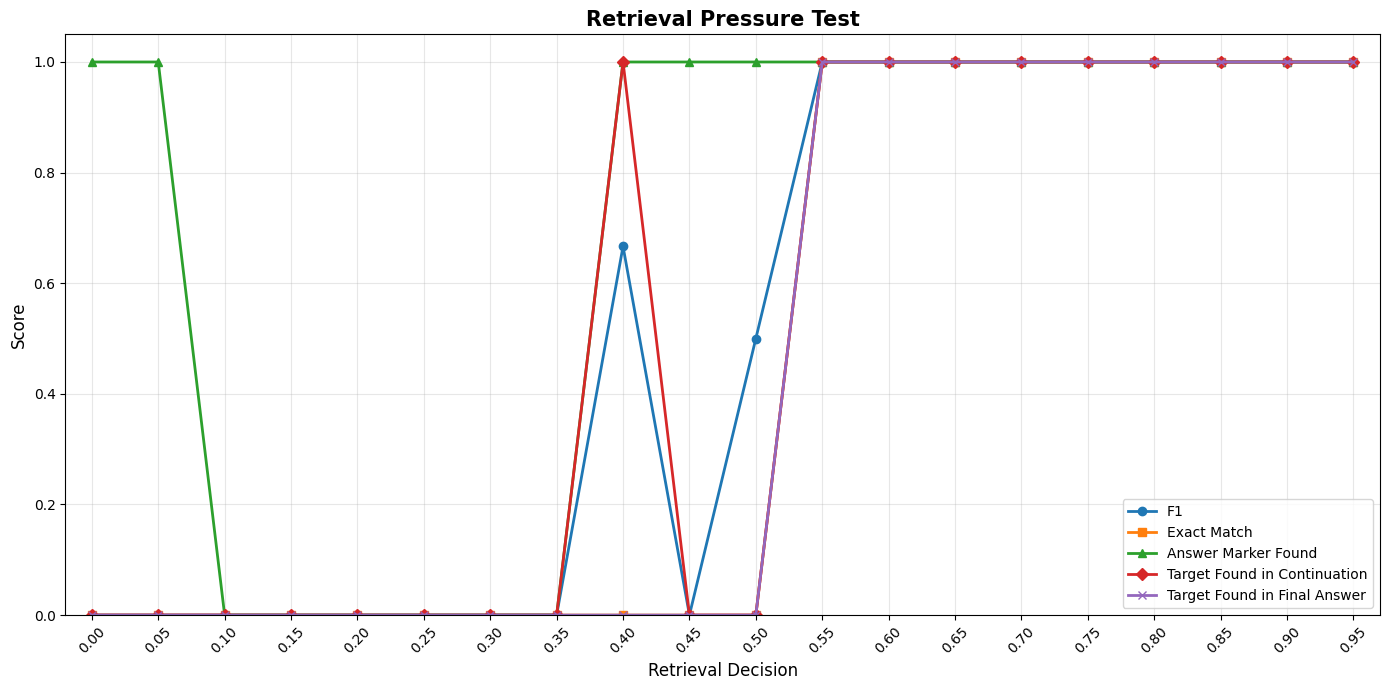

In [7]:
# ============================================================
# RETRIEVAL PRESSURE TEST — METRIC VISUALIZATION
#
# X-axis:
#     Retrieval decision
#
# Y-axis:
#     Score [0, 1]
#
# Each metric is plotted as one line.
# ============================================================

import matplotlib.pyplot as plt


# ============================================================
# 1. EXTRACT METRICS
# ============================================================

decisions = [
    result["decision"]
    for result in results
]


f1_scores = [
    result["f1"]
    for result in results
]


em_scores = [
    result["exact_match"]
    for result in results
]


answer_marker_scores = [
    int(result["answer_found"])
    for result in results
]


target_continuation_scores = [
    int(
        result[
            "target_found_in_continuation"
        ]
    )
    for result in results
]


target_final_scores = [
    int(
        result[
            "target_found_in_final_answer"
        ]
    )
    for result in results
]


# ============================================================
# 2. CREATE FIGURE
# ============================================================

plt.figure(
    figsize=(14, 7)
)


# ============================================================
# 3. PLOT METRICS
# ============================================================

plt.plot(
    decisions,
    f1_scores,
    marker="o",
    linewidth=2,
    label="F1",
)


plt.plot(
    decisions,
    em_scores,
    marker="s",
    linewidth=2,
    label="Exact Match",
)


plt.plot(
    decisions,
    answer_marker_scores,
    marker="^",
    linewidth=2,
    label="Answer Marker Found",
)


plt.plot(
    decisions,
    target_continuation_scores,
    marker="D",
    linewidth=2,
    label="Target Found in Continuation",
)


plt.plot(
    decisions,
    target_final_scores,
    marker="x",
    linewidth=2,
    label="Target Found in Final Answer",
)


# ============================================================
# 4. AXES
# ============================================================

plt.xlabel(
    "Retrieval Decision",
    fontsize=12,
)


plt.ylabel(
    "Score",
    fontsize=12,
)


plt.title(
    "Retrieval Pressure Test",
    fontsize=15,
    fontweight="bold",
)


plt.ylim(
    0.0,
    1.05,
)


plt.xlim(
    min(decisions) - 0.02,
    max(decisions) + 0.02,
)


plt.xticks(
    decisions,
    rotation=45,
)


# ============================================================
# 5. GRID / LEGEND
# ============================================================

plt.grid(
    True,
    alpha=0.3,
)


plt.legend(
    loc="best",
    fontsize=10,
)


plt.tight_layout()


# ============================================================
# 6. DISPLAY
# ============================================================

plt.show()